# Construction Cost Surges and the Delayed Contraction of Housing Starts: Evidence from Korea
## Replication notebook

TaeYoung Kang, SangGun Lee and HoJun Kang

This notebook reproduces every table and figure of the paper from the data in `data/`. The estimation code is in `code/` (R), and the notebook runs it in the order of the paper and displays the results. A full run takes about two minutes.

Requirements: R (4.4) with the packages listed in `requirements.txt`, Python 3 with pandas, and a LaTeX installation with TikZ for Figure 1. The province boundaries for the maps are downloaded at run time from the public `southkorea-maps` repository (Statistics Korea, 2018).

In [1]:
import os, re, subprocess, time
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = os.path.abspath(".")
CODE = os.path.join(ROOT, "code")
pd.set_option("display.max_columns", 20, "display.width", 200)

def tex_table(name):
    """Read a LaTeX tabular written by the R code and return it as a DataFrame (header rows joined)."""
    s = open(os.path.join(CODE, "tables", name + ".tex"), encoding="utf-8").read()
    rows = []
    for line in s.split("\n"):
        line = line.strip()
        if not line.endswith("\\\\") and "\\\\[" not in line:
            continue
        line = re.sub(r"\\\\(\[[^]]*\])?$", "", line)
        line = re.sub(r"\\multicolumn\{\d+\}\{[^}]*\}\{(.*)\}", r"\1", line)
        cells = [c.strip() for c in line.split("&")]
        cells = [re.sub(r"\\(textit|shortstack|text|mathrm)\{([^}]*)\}", r"\2", c) for c in cells]
        cells = [c.replace("$", "").replace("{,}", ",").replace("\\quad", "").replace("^{***}", "***").replace("^{**}", "**")
                  .replace("^{*}", "*").replace("\\,\\dagger", " †").replace("\\%", "%").replace("\\Delta ", "Δ").replace("\\beta", "β").replace("\\theta", "θ")
                  .replace("{+}", "+").replace("\\ ", " ").replace("\\\\", " ").strip() for c in cells]
        rows.append(cells)
    width = max(len(r) for r in rows)
    rows = [r + [""] * (width - len(r)) for r in rows]
    return pd.DataFrame(rows).fillna("")

def show(name, title):
    display(Markdown(f"**{title}**"))
    display(tex_table(name).style.hide(axis="index").hide(axis="columns"))

def fig(file, title, width=700):
    display(Markdown(f"**{title}**"))
    display(Image(filename=os.path.join(CODE, "figures", file), width=width))

## Run the estimation code
Each step writes estimates to `code/out`, LaTeX tables to `code/tables` and figures to `code/figures`.

In [2]:
steps = ["d7_ic_lags", "n0_markov", "n01_descriptive_figures", "n0b_markov_table", "n1_estimate", "n2_tables", "n3_figures",
         "n5_placebo_new", "n6_rest_estimate", "n7_rest_tables", "n8_rest_figures", "n10_v2_extras", "n12_17regions",
         "n13_descriptives", "n17_robust_avg_costlevel", "n19_cap_timing", "n20_credit_demand"]
for d in ("out", "tables", "figures"):
    os.makedirs(os.path.join(CODE, d), exist_ok=True)
for s in steps:
    t0 = time.time()
    r = subprocess.run(["Rscript", s + ".R"], cwd=CODE, capture_output=True, text=True)
    open(os.path.join(CODE, "out", f"log_{s}.txt"), "w").write(r.stdout + r.stderr)
    assert r.returncode == 0, (s, r.stderr[-2000:])
    print(f"{s:28s} {time.time() - t0:5.1f}s")
for s in ["n11_fig_institutions.py", "finalize_tables.py"]:
    r = subprocess.run(["python3", s], cwd=CODE, capture_output=True, text=True)
    assert r.returncode == 0, (s, r.stderr[-2000:])
    print(f"{s:28s} done")

d7_ic_lags                     1.6s


n0_markov                      0.4s


n01_descriptive_figures        1.0s


n0b_markov_table               0.8s


n1_estimate                   76.0s


...

n12_17regions                  1.2s
n13_descriptives               0.2s


n17_robust_avg_costlevel       2.6s


n19_cap_timing                 1.1s


n20_credit_demand              3.5s


n11_fig_institutions.py      done
finalize_tables.py           done


## Section 4. Institutions and data

**Figure 1. Housing development in Korea**

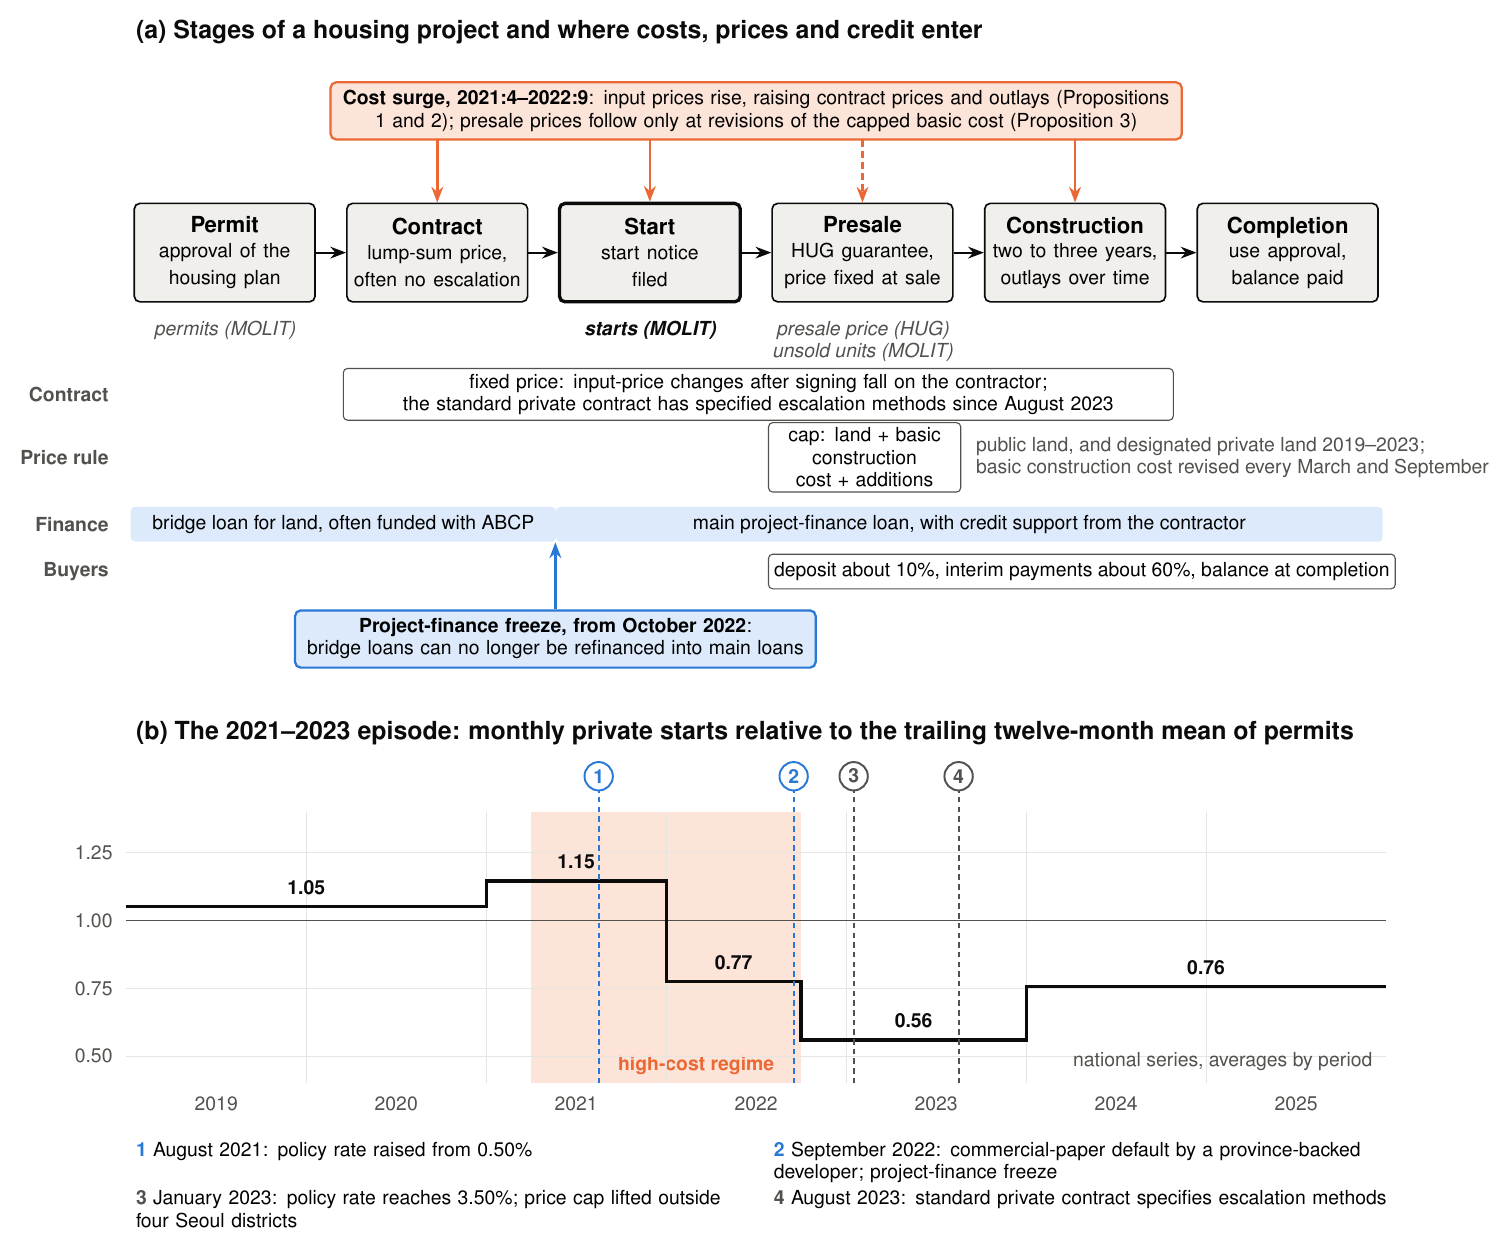

In [3]:
fig("fig_institutions.png", "Figure 1. Housing development in Korea", 900)

In [4]:
show("tab_t1_new", "Table 1. Summary statistics")

**Table 1. Summary statistics**

Variable,Obs.,Mean,Std. dev.,Min.,Max.
Dependent variable,,,,,
Housing starts (log),"1,448",6.900,1.699,0.000,10.418
Main regressor,,,,,
"Construction cost growth (%, YoY)","1,448",3.738,3.144,-0.271,14.130
High-cost regime (dummy),"1,448",0.099,0.299,0.000,1.000
Housing-market controls (log),,,,,
Housing permits (monthly),"1,448",7.130,1.585,0.000,10.370
Unsold housing units,"1,448",7.261,1.459,1.099,10.254
Registered households,"1,448",14.062,0.845,12.914,15.628
Apartment transaction volume,"1,448",8.538,0.809,6.518,10.886


**Figure 2. Construction cost growth and the high-cost regime**

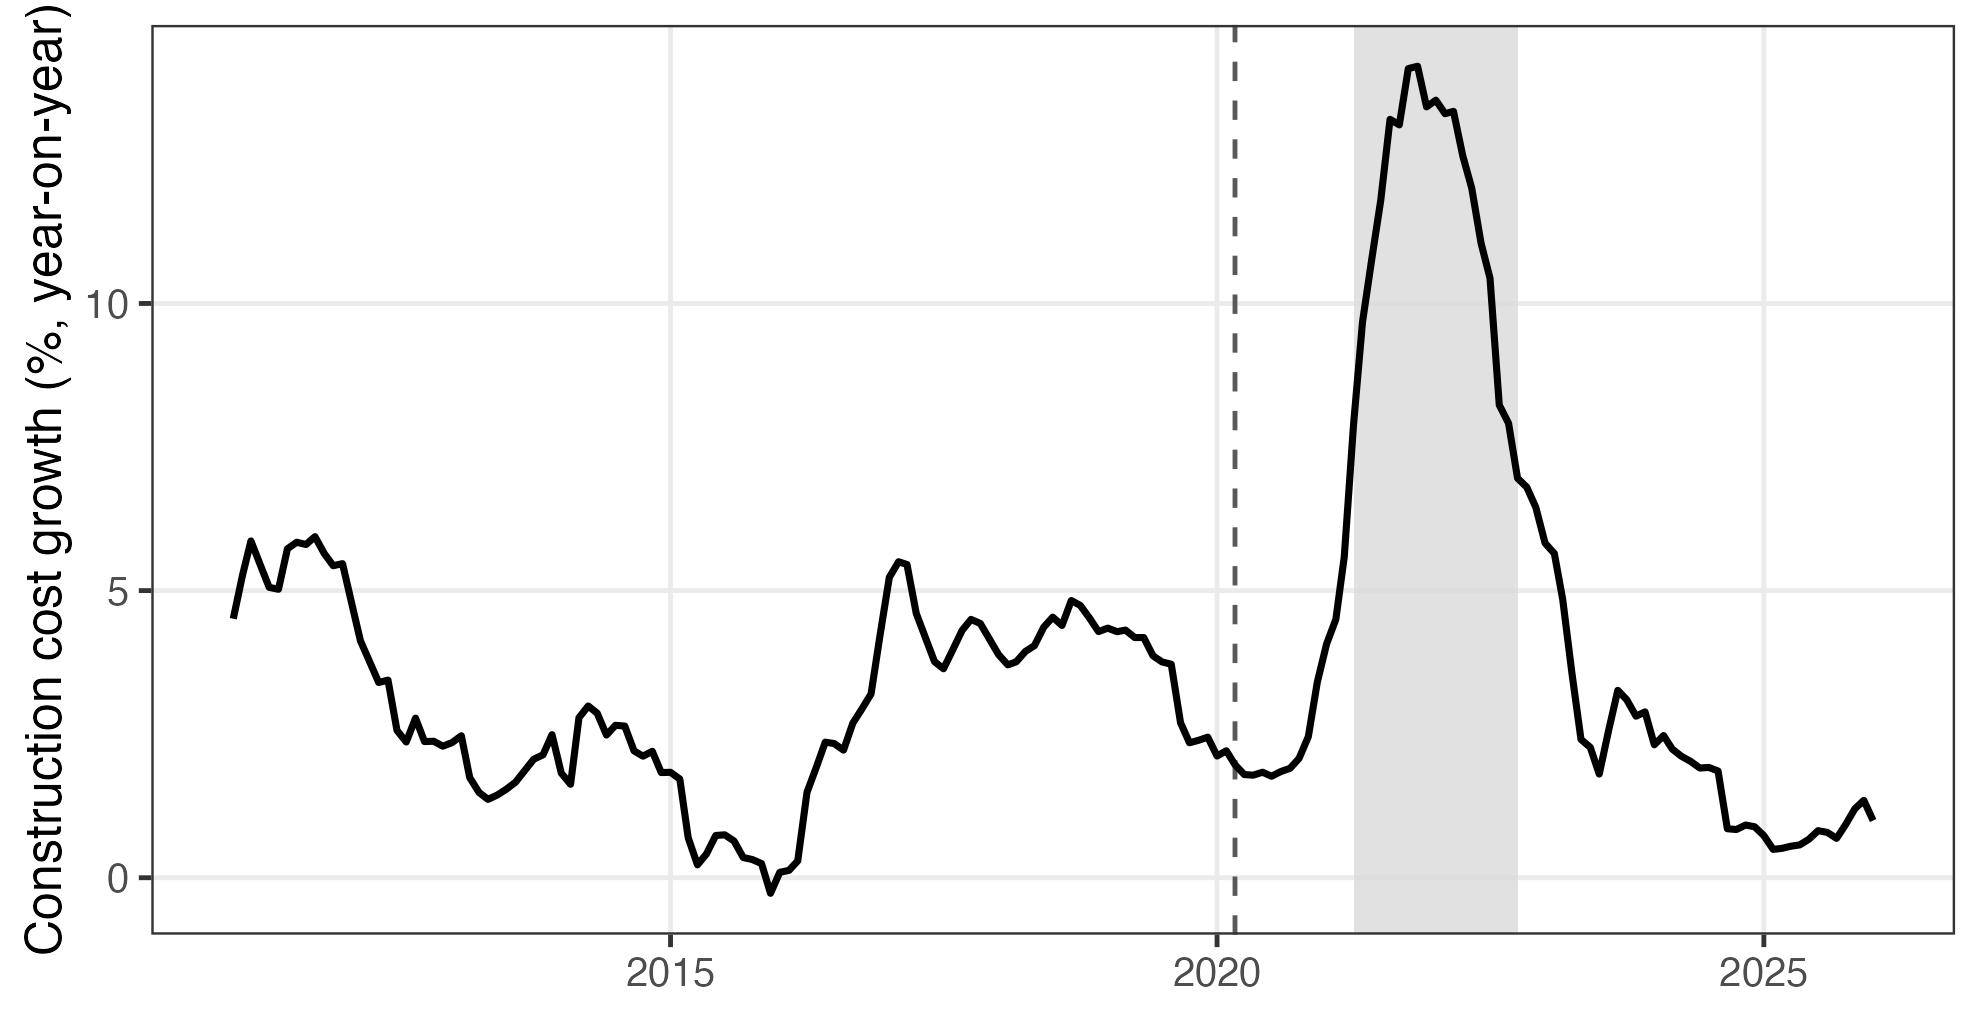

**Figure 3. Housing starts around the cost surge, selected regions**

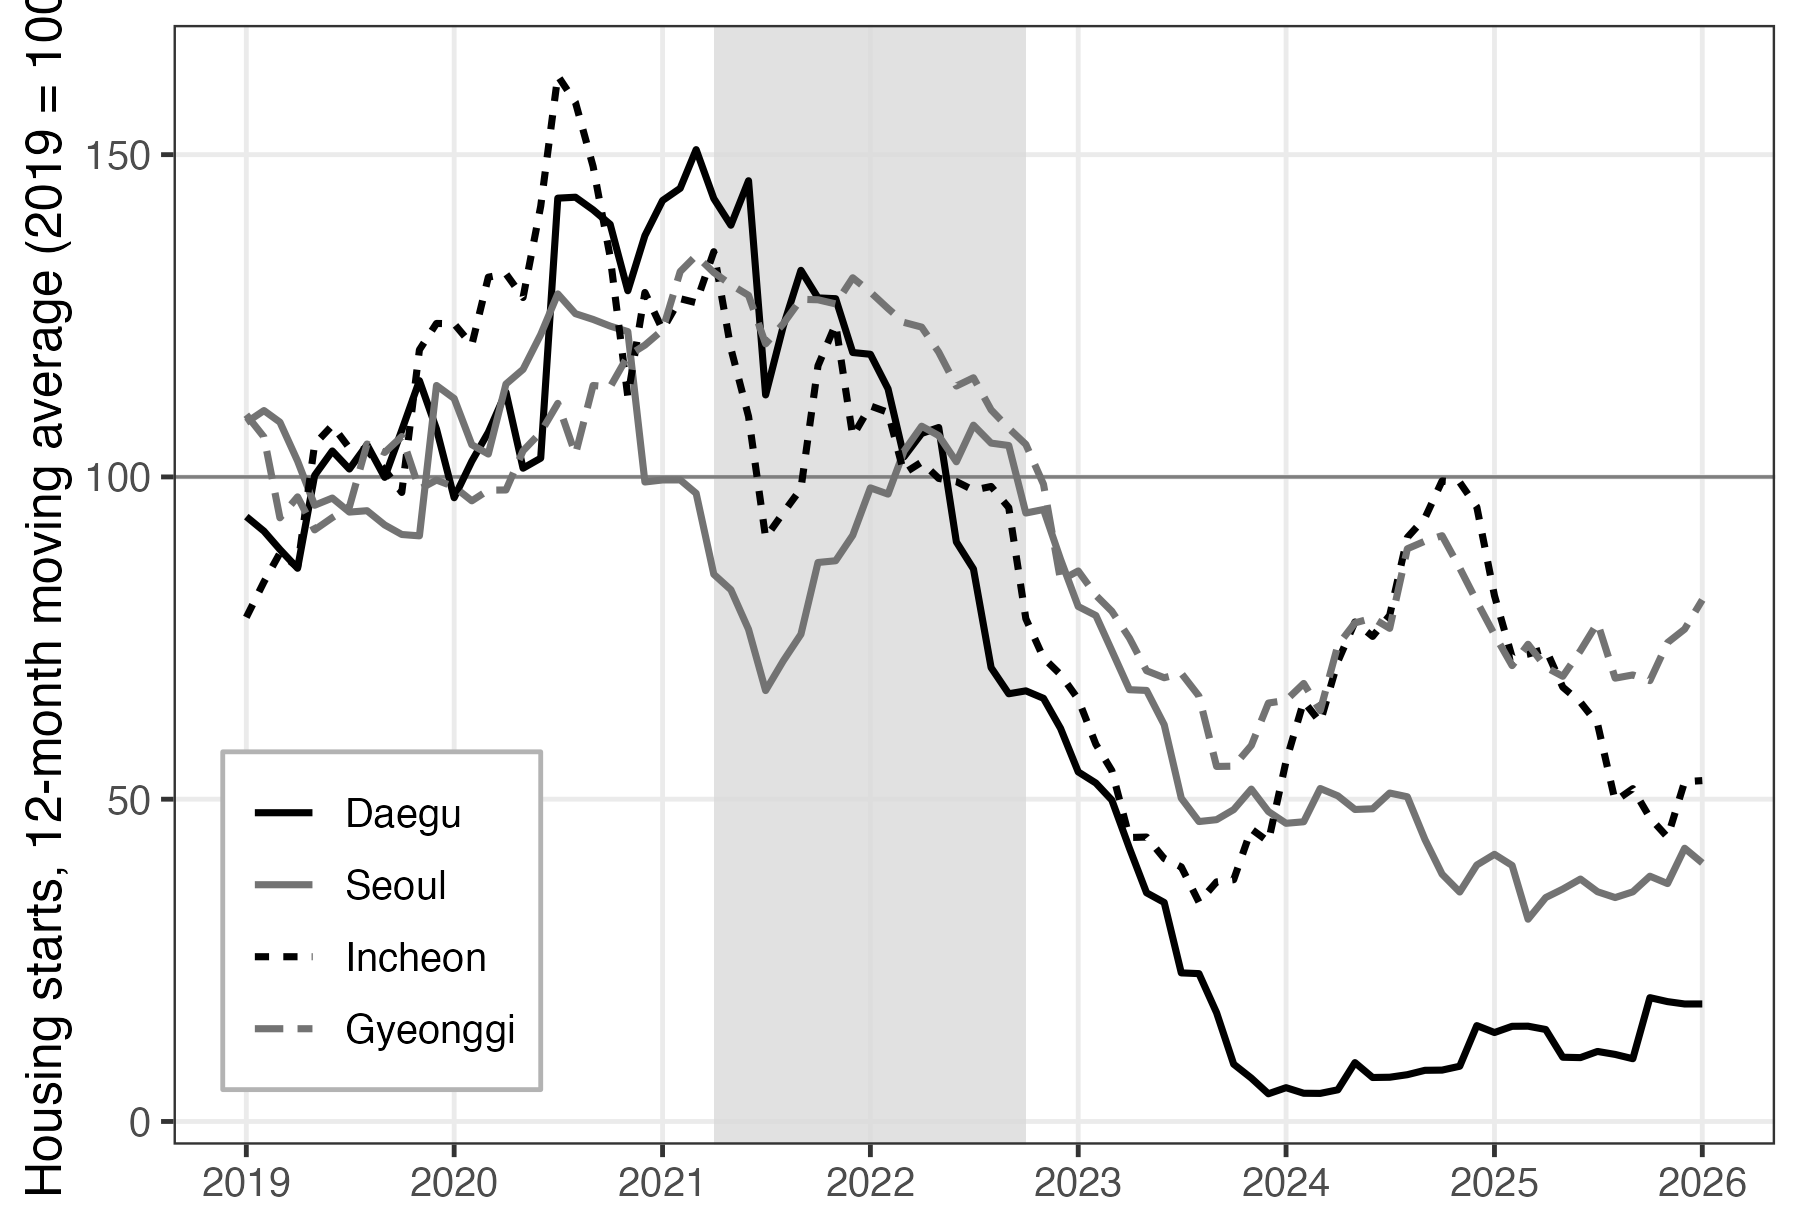

In [5]:
fig("fig_cost_growth.png", "Figure 2. Construction cost growth and the high-cost regime")
fig("fig_event.png", "Figure 3. Housing starts around the cost surge, selected regions", 600)

In [6]:
show("tab_t2_new", "Table 2. Regional structure and the surge in unsold inventory")

**Table 2. Regional structure and the surge in unsold inventory**

,Sample mean (log),Surge change,,,,
Region,Starts,Permits (monthly),Unsold,Transactions,Price index,ΔUnsold
Seoul,8.30,8.42,6.14,9.05,4.73,+29.2
Busan,7.27,7.47,7.81,8.72,4.55,-65.3
Daegu,6.29,6.61,7.53,8.40,4.56,+117.5
Incheon,7.06,7.21,7.61,8.58,4.64,-46.6
Gwangju,5.84,6.16,5.85,8.01,4.62,-57.2
Daejeon,5.81,6.15,6.93,7.86,4.74,-47.2
Ulsan,5.63,5.90,7.12,7.69,4.56,-40.7
Gyeonggi,8.99,9.12,9.10,10.00,4.70,-84.0


## Section 7. Results

In [7]:
show("tab_t3_main", "Table 3. The dynamic effect of construction cost growth on housing starts")

**Table 3. The dynamic effect of construction cost growth on housing starts**

,"Dependent variable: \ln(1+starts)_{i,t+h}-\ln(1+starts)_{i,t-1}",,,,,,,
Horizon h (months),0,3,6,9,12,15,18,24
,(1),(2),(3),(4),(5),(6),(7),(8)
\multicolumn{9}{@{}l}{Panel A. Average response},,,,,,,,
Construction cost growth c_t,0.105,0.023,-0.004,-0.027,0.083,0.051,-0.120,-0.214***
,(0.089),(0.073),(0.079),(0.075),(0.097),(0.080),(0.091),(0.074)
R^2,0.485,0.502,0.456,0.464,0.459,0.482,0.453,0.484
\multicolumn{9}{@{}l}{Panel B. High-cost regime},,,,,,,,
"Cost growth, ordinary regime (β_h)",0.072,-0.001,-0.027,-0.041,0.117,0.065,-0.080,-0.186**
,(0.093),(0.080),(0.078),(0.083),(0.100),(0.085),(0.086),(0.082)
"Total effect, high-cost regime (β_h+θ_h)",0.105,-0.015,0.066,0.054,0.154,-0.185*,-0.337***,-0.181***


**Figure 4(a). Average response**

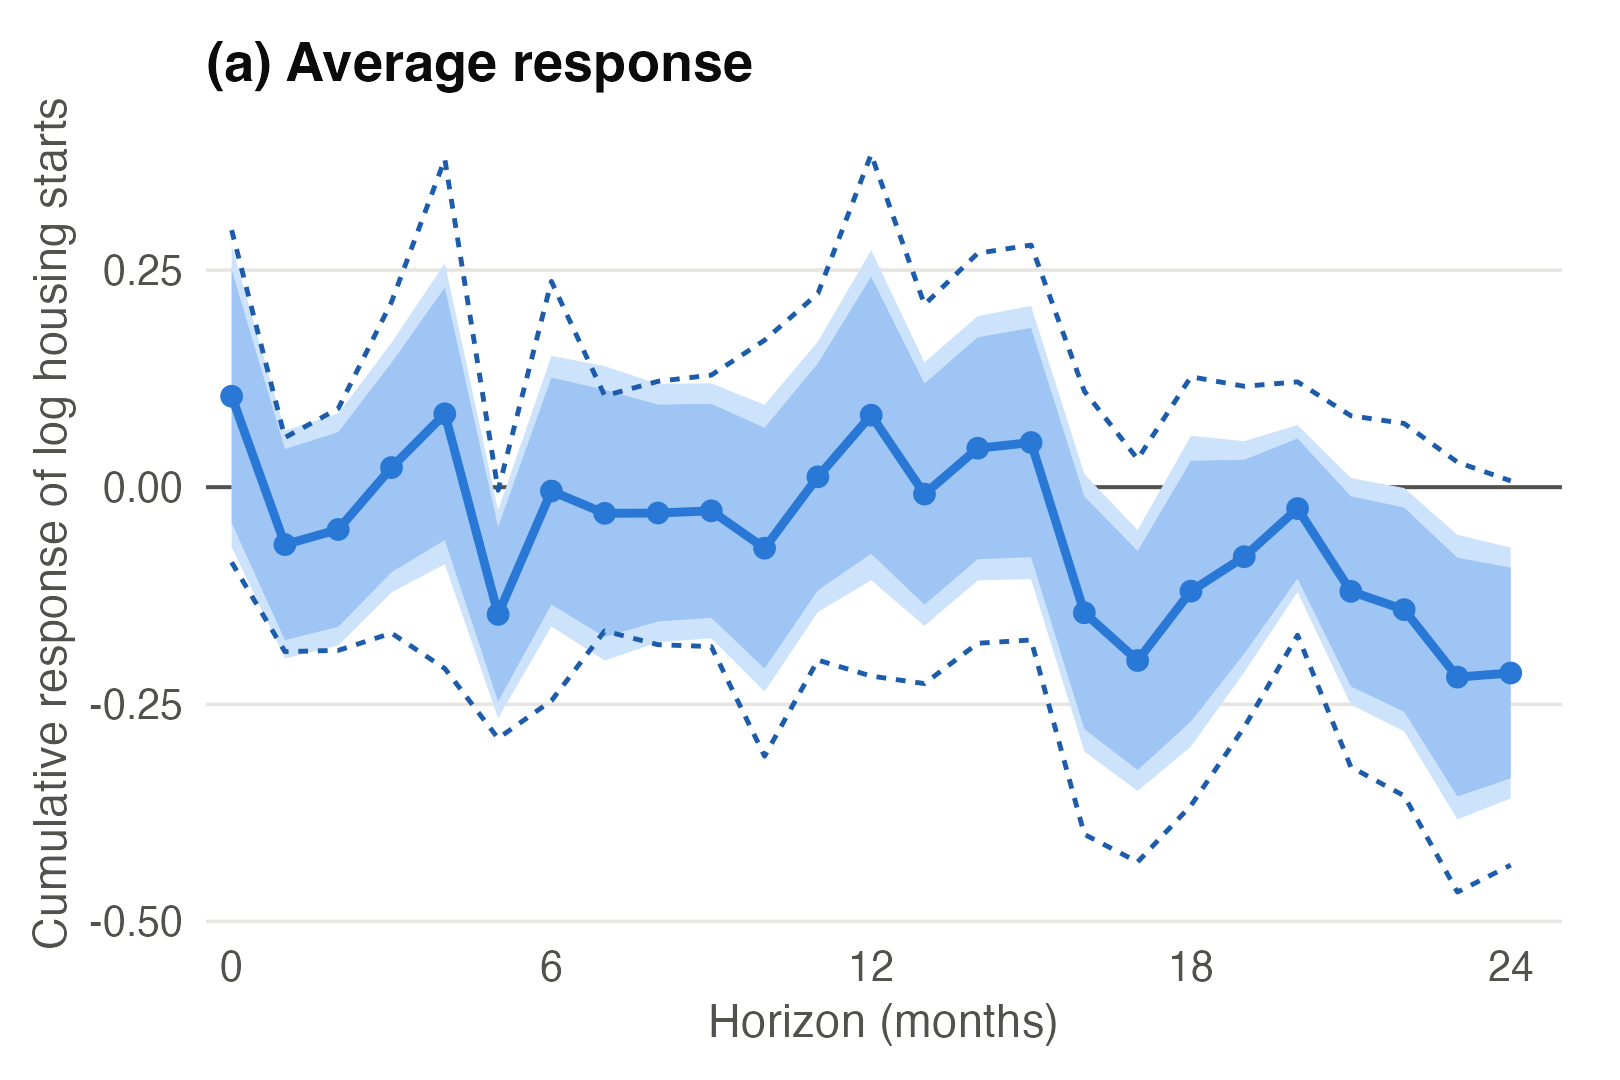

**Figure 4(b). Total effect in the high-cost regime**

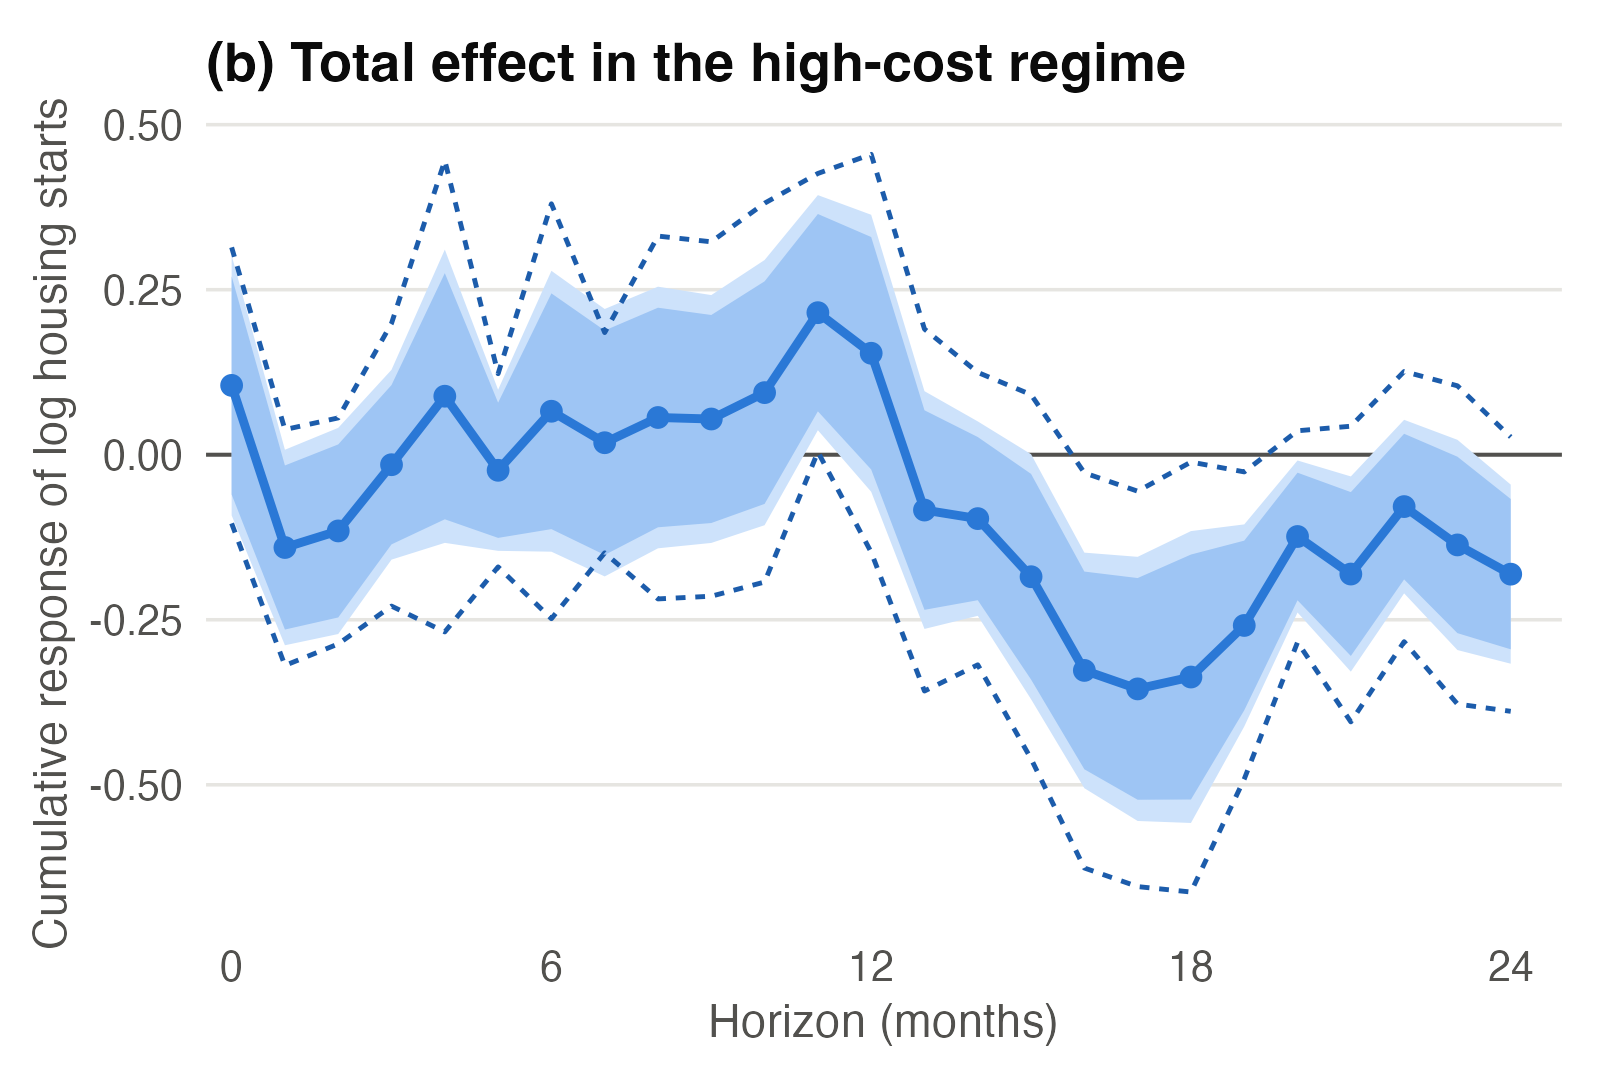

In [8]:
fig("fig3a_avg_irf_new.png", "Figure 4(a). Average response", 520)
fig("fig3b_regime_irf_new.png", "Figure 4(b). Total effect in the high-cost regime", 520)

**Figure 5. High-cost-regime responses in placebo eighteen-month windows**

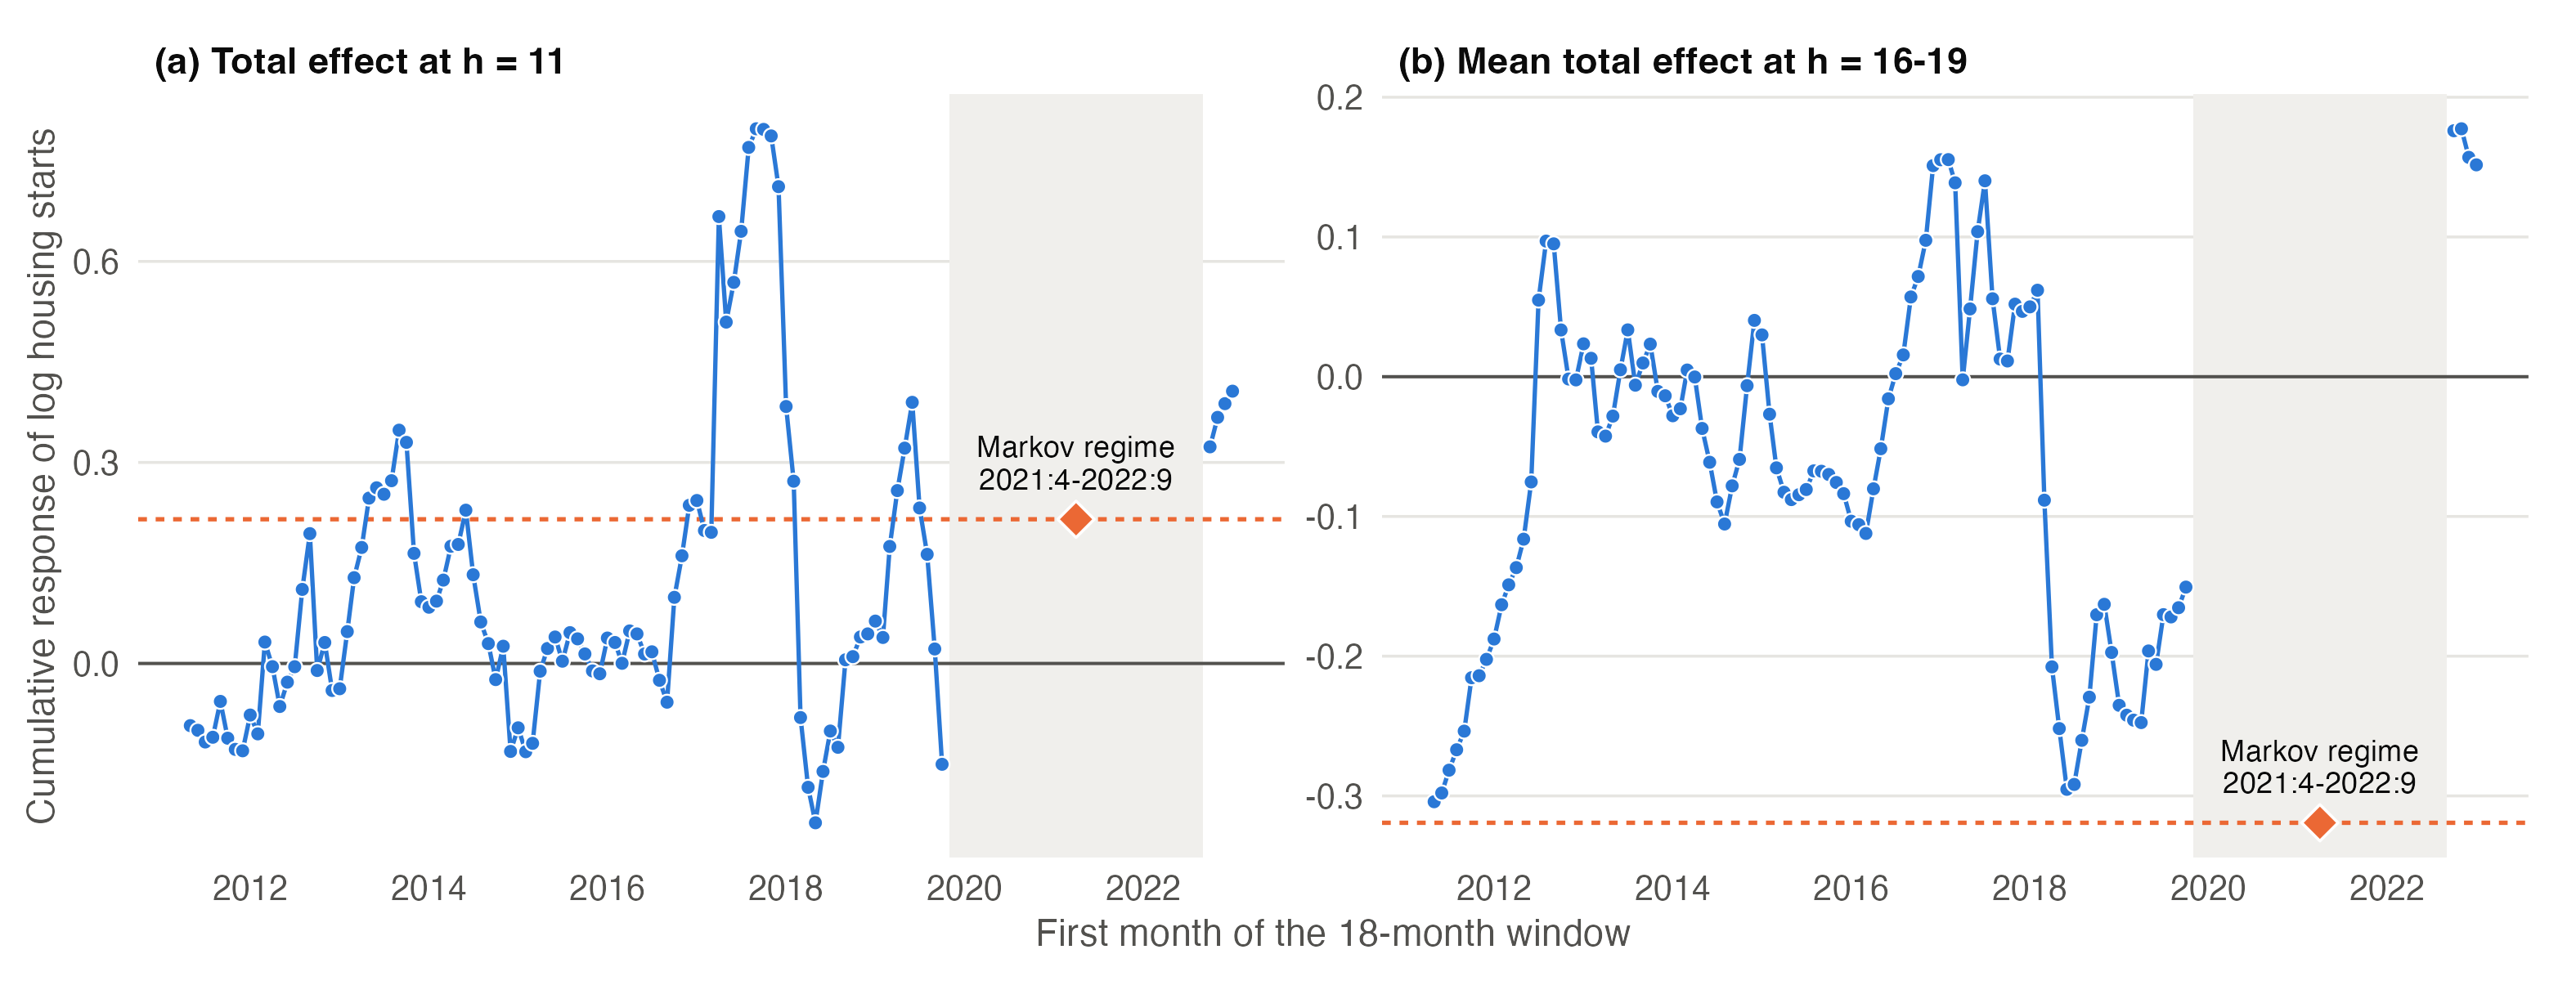

In [9]:
fig("fig4_placebo_new.png", "Figure 5. High-cost-regime responses in placebo eighteen-month windows", 900)

In [10]:
show("tab_t4_new", "Table 4. Regional heterogeneity in the housing-start response")

**Table 4. Regional heterogeneity in the housing-start response**

,"Dependent variable: cumulative change in log housing starts, t-1 to t+h",,,,
Region-specific total effect of c_t,h=0,h=6,h=12,h=18,h=24
,(1),(2),(3),(4),(5)
Seoul (reference),0.087,0.004,0.096,-0.101,-0.185**
,(0.092),(0.082),(0.100),(0.097),(0.077)
Busan,0.071,-0.029,0.083,-0.091,-0.195***
,(0.090),(0.086),(0.107),(0.086),(0.069)
Daegu,0.161*,0.025,0.044,-0.235**,-0.363*** †
,(0.090),(0.089),(0.092),(0.102),(0.116)
Incheon,0.098,-0.016,0.085,-0.078,-0.113
,(0.091),(0.080),(0.099),(0.089),(0.090)


**Figure 6. Regional response at six, twelve, eighteen and twenty-four months**

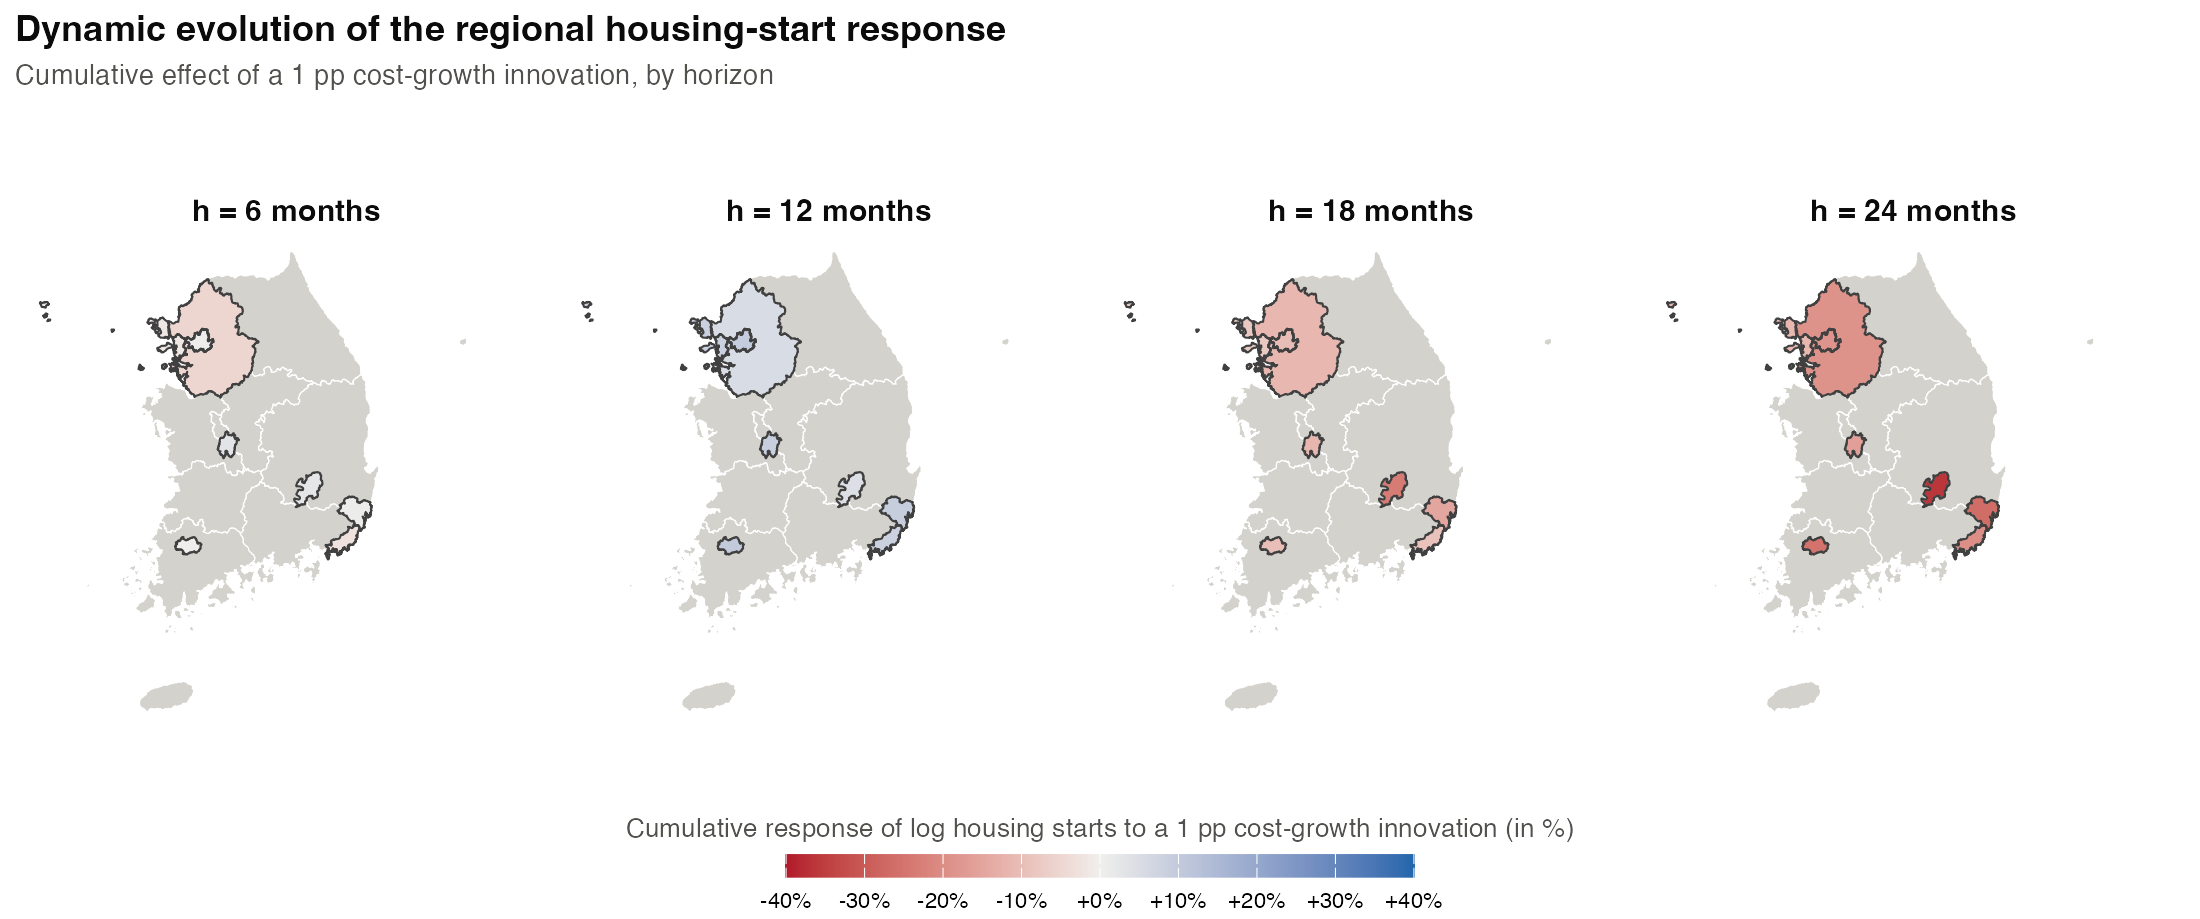

**Figure 7. Regional response at eighteen months**

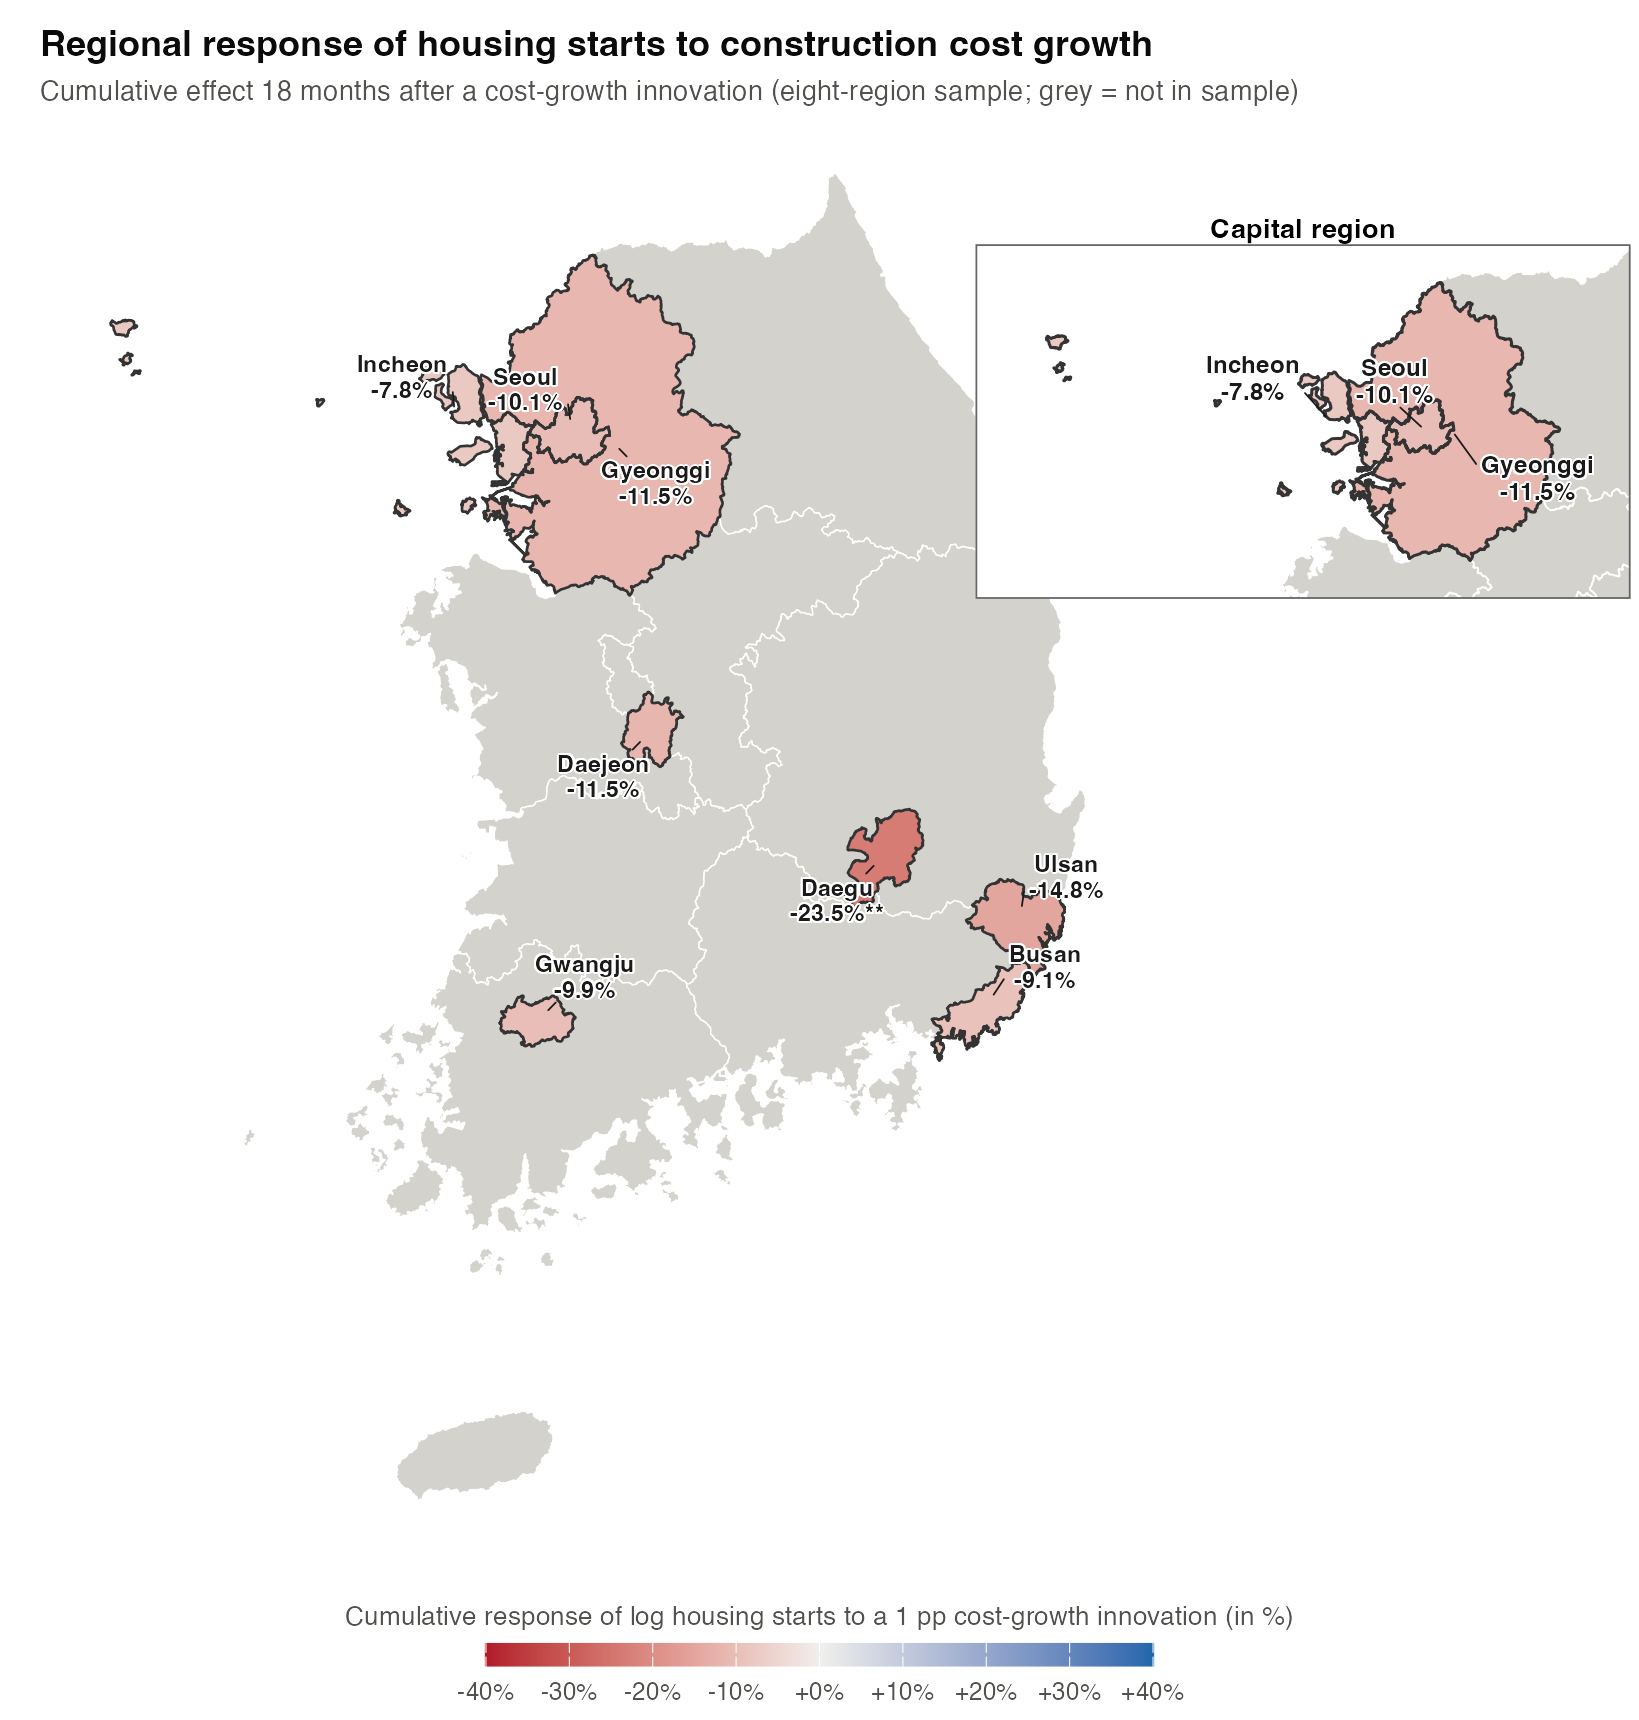

In [11]:
fig("fig5_map_evolution_new.png", "Figure 6. Regional response at six, twelve, eighteen and twenty-four months", 900)
fig("fig6_map_h18_new.png", "Figure 7. Regional response at eighteen months", 600)

In [12]:
show("tab_t5_new", "Table 5. The effect of construction cost growth on new-sale prices")
show("tab_t8_cap_timing", "Table 6. Presale announcements around the revisions of the basic construction cost")

**Table 5. The effect of construction cost growth on new-sale prices**

,"Dependent variable: \ln p_{i,t+h}-\ln p_{i,t-1}, average new-sale price",,,,,
Horizon h (months),0,5,10,15,18,24
,(1),(2),(3),(4),(5),(6)
\multicolumn{7}{@{}l}{Panel A. Average response},,,,,,
Construction cost growth c_t,-0.001,0.002,0.010*,0.018***,0.013*,0.016**
,(0.002),(0.006),(0.006),(0.006),(0.007),(0.008)
R^2,0.059,0.223,0.274,0.358,0.396,0.492
\multicolumn{7}{@{}l}{Panel B. High-cost regime},,,,,,
"Cost growth, ordinary regime (β_h)",0.001,0.007,0.015**,0.028***,0.024***,0.031***
,(0.002),(0.006),(0.007),(0.009),(0.008),(0.011)
"Total effect, high-cost regime (β_h+θ_h)",0.000,0.006,0.006,0.016*,0.000,0.009


**Table 6. Presale announcements around the revisions of the basic construction cost**

,PPML; count in a 45-day half-window,,,
,Announcements},\multicolumn{2}{c}{Units offered,,
,Revision dates,Placebo dates,Revision dates,Placebo dates
,(1),(2),(3),(4)
Post \times capped,0.633***,-0.265,0.659**,-0.217
,(0.233),(0.191),(0.282),(0.257)
"Implied ratio, \exp(\hat b)",1.88,0.77,1.93,0.80
Post,0.123,-0.042,0.095,-0.118
,(0.133),(0.097),(0.191),(0.151)
Date \times capped fixed effects,Yes,Yes,Yes,Yes
Dates (clusters),13,12,13,12


In [13]:
show("tab_t10_paths", "Table 7. The response of housing starts with the paths of credit and demand held fixed, and before 2020")

**Table 7. The response of housing starts with the paths of credit and demand held fixed, and before 2020**

,Cumulative change in log starts; OLS local projections,,,,,
,,Realized changes from t-1 to t+h added,Surprises,,,
,Baseline,Yield,Yield and,Resale,All four,to 2019:12
,,,spread,price,,
,(1),(2),(3),(4),(5),(6)
"\multicolumn{7}{@{}l}{Panel A. Average response, β_h}",,,,,,
h=0,0.105,0.120,0.144*,0.109,0.152*,0.072
,(0.089),(0.087),(0.087),(0.088),(0.083),(0.099)
h=3,0.023,0.018,0.047,0.019,0.062,-0.015
,(0.073),(0.076),(0.083),(0.074),(0.081),(0.090)
h=6,-0.004,-0.012,-0.003,-0.010,-0.002,-0.055


In [14]:
import json
conv = json.load(open(os.path.join(CODE, "out", "conversion_steps.json")))
print("Two-step fall in the ratio of starts to recent permits (Section 7.5):", conv)

Two-step fall in the ratio of starts to recent permits (Section 7.5): {'means': {'2012-14': 0.885102, '2015-18': 0.878117, '2019-20': 1.051323, '2021': 1.145479, '2022:1-9': 0.774768, '2022:10-2023': 0.559523, '2024-': 0.755961}, 'n': {'2012-14': 36, '2015-18': 48, '2019-20': 24, '2021': 12, '2022:1-9': 9, '2022:10-2023': 15, '2024-': 25}, 'step1_2021_to_2022q1_3': {'b': -0.370711, 'se': 0.077223, 'p': 3.573384e-06}, 'step2_to_freeze': {'b': -0.215245, 'se': 0.099788, 'p': 0.032478}, 'total_2021_to_freeze': {'b': -0.585956, 'se': 0.10149, 'p': 3.856559e-08}, 'sample': ['2012-01-01', '2026-01-01'], 'nw_lag': 12}


In [15]:
show("tab_t6_new", "Table 8. Robustness of the high-cost-regime total effect")
show("tab_t7_robust_avg", "Table 9. Robustness of the average and high-cost-regime responses")

**Table 8. Robustness of the high-cost-regime total effect**

,Dependent variable: cumulative change in log housing starts; OLS local projections,,,,,,
,Lag structure},\multicolumn{3}{c}{Regime definition and sample,,,,,
,Baseline,2 lags,3 lags,Regime lags,Top-10%,Excl.,Excl.
,4 lags,,,4 lags,regime,Gyeonggi,Daegu
,(1),(2),(3),(4),(5),(6),(7)
"\multicolumn{8}{@{}l}{Total effect in the high-cost regime, β_h+θ_h}",,,,,,,
h=0,0.105,0.084,0.085,0.251*,0.095,0.115,0.064
,(0.100),(0.101),(0.103),(0.138),(0.098),(0.109),(0.103)
h=5,-0.024,-0.008,-0.014,0.143,-0.033,-0.024,0.002
,(0.062),(0.056),(0.060),(0.158),(0.056),(0.068),(0.074)
h=10,0.094,0.171*,0.124,-0.069,0.075,0.116,0.176


**Table 9. Robustness of the average and high-cost-regime responses**

,Cumulative change in log starts; OLS local projections,,,
,Baseline,Excluding,Weighted by,Same-month
,,Daegu,region size,macro controls
,(1),(2),(3),(4)
"\multicolumn{5}{@{}l}{Panel A. Average response, β_h}",,,,
h=0,0.105,0.130,0.078,0.170**
,(0.089),(0.095),(0.069),(0.082)
h=3,0.023,0.017,-0.101,-0.045
,(0.073),(0.086),(0.067),(0.084)
h=6,-0.004,0.026,-0.013,0.027
,(0.079),(0.080),(0.058),(0.075)


## Appendix A

In [16]:
show("tab_tA1_markov", "Table A.1. Markov-switching classification of the high-cost regime")
show("tab_tA2_new", "Table A.2. Coefficient estimates, average response")
show("tab_tA5_ic", "Table A.3. Lag-length selection")

**Table A.1. Markov-switching classification of the high-cost regime**

"\multicolumn{3}{@{}l}{Panel A. Estimated regime means (cost growth, % YoY)}",,
Low-cost regime,2.857,
High-cost regime,11.643,
\multicolumn{3}{@{}l}{Panel B. Transition probability matrix},,
,To low-cost,To high-cost
From low-cost,0.994,0.006
From high-cost,0.055,0.945
\multicolumn{3}{@{}l}{Panel C. Classification},,
Smoothed-probability cutoff,0.50,
Share of months in high-cost regime,9.9%,
High-cost regime span,2021:4--2022:9,


**Table A.2. Coefficient estimates, average response**

,"Dependent variable: cumulative change in log housing starts, t-1 to t+h",,,,
Regressor,h=0,h=6,h=12,h=18,h=24
,(1),(2),(3),(4),(5)
Construction cost growth c_t,0.105,-0.004,0.083,-0.120,-0.214***
,(0.089),(0.079),(0.097),(0.091),(0.074)
\multicolumn{6}{@{}l}{Sum of coefficients on lags 1--4},,,,,
Log housing starts,-0.683***,-0.721***,-0.844***,-0.870***,-1.016***
,(0.060),(0.042),(0.044),(0.098),(0.113)
Construction cost growth,-0.118,0.005,-0.090,0.056,0.208**
,(0.085),(0.075),(0.089),(0.088),(0.082)
"Housing permits (monthly, log)",0.293***,0.129**,0.060,-0.076,0.003


**Table A.3. Lag-length selection**

Lag length p,AIC,HQ,BIC
1,-34.535,-34.165,\textbf{-33.624}
2,-35.157,\textbf{-34.417},-33.334
3,\textbf{-35.201},-34.092,-32.468
4,-35.022,-33.542,-31.377
5,-34.917,-33.068,-30.361
6,-34.897,-32.678,-29.430
7,-34.794,-32.205,-28.416
8,-34.722,-31.763,-27.432
9,-34.794,-31.466,-26.594
10,-34.605,-30.907,-25.493


In [17]:
show("tab_t9_episode", "Table A.4. Responses of credit and resale-market conditions to construction cost growth")
show("tab_tA6_17reg", "Table A.5. Seventeen provinces and metropolitan cities")

**Table A.4. Responses of credit and resale-market conditions to construction cost growth**

,National series},\multicolumn{2}{c}{Eight regions,,
,Treasury,Corporate,Resale,Apartment
,yield,spread,prices,transactions
,(1),(2),(3),(4)
"\multicolumn{5}{@{}l}{Panel A. Average response, β_h}",,,,
h=0,0.037,-0.020**,0.001,-0.012
,(0.024),(0.009),(0.001),(0.024)
h=3,0.043,-0.080**,0.003,-0.044
,(0.047),(0.032),(0.003),(0.039)
h=6,0.073,-0.057*,0.004,-0.011
,(0.047),(0.031),(0.005),(0.041)


**Table A.5. Seventeen provinces and metropolitan cities**

,"Dependent variable: \ln(1+starts)_{i,t+h}-\ln(1+starts)_{i,t-1}",,,,,,,
Horizon h (months),0,3,6,9,12,15,18,24
,(1),(2),(3),(4),(5),(6),(7),(8)
\multicolumn{9}{@{}l}{Panel A. Average response},,,,,,,,
Construction cost growth c_t,0.031,-0.020,-0.034,-0.065,-0.026,-0.033,-0.176***,-0.105**
,(0.059),(0.060),(0.055),(0.044),(0.055),(0.067),(0.055),(0.048)
R^2,0.452,0.480,0.468,0.490,0.464,0.485,0.486,0.490
\multicolumn{9}{@{}l}{Panel B. High-cost regime},,,,,,,,
"Cost growth, ordinary regime (β_h)",-0.006,-0.062,-0.059,-0.062,-0.011,-0.015,-0.154***,-0.095*
,(0.058),(0.061),(0.056),(0.046),(0.065),(0.067),(0.050),(0.057)
"Total effect, high-cost regime (β_h+θ_h)",0.015,-0.058,0.033,-0.001,0.015,-0.236***,-0.307***,-0.032
